# Blackjack with Monte Carlo

Project 3.1 for 6COM2007. The task is to implement Sutton & Barto's Blackjack environment and apply two Monte Carlo control methods to it.

structured in roughly the order I wrote things: environment first, then both algorithms, then the plots, then a short evaluation.

## The environment

Following Sutton & Barto pretty closely. State is (player_sum, dealer_showing, usable_ace). Actions are 0 = stick, 1 = hit. Reward is +1/0/-1 only at the terminal step. Cards are drawn from an "infinite deck" - i.e. with replacement, so card counting isn't a thing here.

In [49]:
import numpy as np
import random
from collections import defaultdict
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# seed both because we use both
SEED = 0
random.seed(SEED)
np.random.seed(SEED)

In [50]:
def draw_card():
    # 13 ranks, but J/Q/K all count as 10 - clip
    card = random.randint(1, 13)
    return min(card, 10)

def hand_value(hand):
    # Returns the best total and whether an ace is being counted as 11.
    # If we have an ace and treating it as 11 doesn't bust, do that.
    total = sum(hand)
    if 1 in hand and total + 10 <= 21:
        return total + 10, True
    return total, False

def is_bust(hand):
    return hand_value(hand)[0] > 21

In [51]:
class BlackjackEnv:
    def reset(self):
        self.player = [draw_card(), draw_card()]
        self.dealer = [draw_card(), draw_card()]
        # Below 12 just always hit (can't bust), so skip those states.
        while hand_value(self.player)[0] < 12:
            self.player.append(draw_card())
        return self._state()

    def reset_exploring(self, player_sum, dealer_showing, usable_ace):
        # Force a specific starting state. Only used by Exploring Starts.
        self.dealer = [dealer_showing, draw_card()]
        if usable_ace:
            # Ace + whatever else gets to player_sum
            self.player = [1, player_sum - 11]
        else:
            # Two-card hand summing to player_sum, no usable ace
            c1 = min(10, player_sum - 2)
            c2 = player_sum - c1
            self.player = [c1, c2]
        return self._state()

    def _state(self):
        ps, ua = hand_value(self.player)
        return (ps, self.dealer[0], int(ua))

    def step(self, action):
        if action == 1:
            # hit
            self.player.append(draw_card())
            if is_bust(self.player):
                return self._state(), -1, True
            return self._state(), 0, False

        # stick - dealer plays out their fixed rule
        while hand_value(self.dealer)[0] < 17:
            self.dealer.append(draw_card())

        p = hand_value(self.player)[0]
        d = hand_value(self.dealer)[0]
        if d > 21 or p > d:
            return self._state(), 1, True
        if p < d:
            return self._state(), -1, True
        return self._state(), 0, True

In [52]:
env = BlackjackEnv()
outcomes = {"win": 0, "lose": 0, "draw": 0}
for _ in range(10_000):
    env.reset()
    _, r, _ = env.step(0)
    outcomes["win" if r == 1 else "lose" if r == -1 else "draw"] += 1
print(outcomes, "-> win rate:", outcomes["win"] / 10_000)

{'win': 4093, 'lose': 5212, 'draw': 695} -> win rate: 0.4093


About 41% wins. Sounds right.

## Monte Carlo with Exploring Starts

The idea is that to make sure every (state, action) pair gets enough samples for Q to settle, start each episode from a uniformly random pair. After that the policy is fully greedy. This is theoretically clean but obviously can't be done outside a simulator - real environments don't let you teleport.

Update rule is the standard incremental mean: Q <- Q + (G - Q) / N where N counts visits. With γ=1 because blackjack episodes are short and the only reward that matters is at the terminal step.

In [53]:
def mc_exploring_starts(num_episodes=500_000, seed=0):
    random.seed(seed); np.random.seed(seed)
    env = BlackjackEnv()
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(lambda: np.zeros(2))

    for ep in range(num_episodes):
        # exploring start: random (state, action)
        p_sum = random.randint(12, 21)
        d_show = random.randint(1, 10)
        u_ace = random.randint(0, 1)
        state = env.reset_exploring(p_sum, d_show, u_ace)
        action = random.randint(0, 1)

        # play out the rest greedily
        episode = []
        done = False
        while not done:
            next_state, reward, done = env.step(action)
            episode.append((state, action, reward))
            state = next_state
            if not done:
                action = int(np.argmax(Q[state]))

        # first visit MC update, walking the episode backwards
        G = 0
        visited = set()
        for (s, a, r) in reversed(episode):
            G = r + G
            if (s, a) not in visited:
                visited.add((s, a))
                N[s][a] += 1
                Q[s][a] += (G - Q[s][a]) / N[s][a]

    return Q, N

In [54]:
print("Training MC-ES (500k episodes)...")
Q_es, N_es = mc_exploring_starts(num_episodes=500_000, seed=0)
print(f"States visited: {len(Q_es)} / 200")

Training MC-ES (500k episodes)...
States visited: 200 / 200


## On-policy first-visit MC, epsilon-soft

Same MC update, different way of handling exploration. Instead of forcing random starts, the policy itself stays slightly random - 10% of the time it picks an action uniformly, otherwise it picks greedily. This gets coverage without needing to teleport, but the trade-off is the policy isn't strictly greedy anymore so the learned Q is a bit lower than the actual optimum.

I went with e = 0.1 because that's the standard default in Sutton & Barto.

In [55]:
def mc_epsilon_soft(num_episodes=500_000, epsilon=0.1, seed=0):
    random.seed(seed); np.random.seed(seed)
    env = BlackjackEnv()
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(lambda: np.zeros(2))

    def policy(state):
        if random.random() < epsilon:
            return random.randint(0, 1)
        return int(np.argmax(Q[state]))

    for ep in range(num_episodes):
        state = env.reset()
        episode = []
        done = False
        while not done:
            action = policy(state)
            next_state, reward, done = env.step(action)
            episode.append((state, action, reward))
            state = next_state

        # same update as before
        G = 0
        visited = set()
        for (s, a, r) in reversed(episode):
            G = r + G
            if (s, a) not in visited:
                visited.add((s, a))
                N[s][a] += 1
                Q[s][a] += (G - Q[s][a]) / N[s][a]

    return Q, N

In [56]:
print("Training on-policy e-soft (epsilon=0.1, 500k episodes)...")
Q_eps, N_eps = mc_epsilon_soft(num_episodes=500_000, epsilon=0.1, seed=0)
print(f"States visited: {len(Q_eps)} / 200")

Training on-policy e-soft (epsilon=0.1, 500k episodes)...
States visited: 200 / 200


## Plotting the value function and policy

Two helpers to pull V(s) = max_a Q(s, a) and the greedy policy out of the Q-tables, then a 3D surface plot for V and a 2D heatmap for the policy. Splitting the usable ace and no usable ace cases into separate panels since they end up with noticeably different shapes.

In [57]:
def extract_value(Q):
    # axis 0 = usable ace flag, axis 1 = player sum (12..21), axis 2 = dealer (1..10)
    V = np.zeros((2, 10, 10))
    for u in range(2):
        for ps in range(12, 22):
            for ds in range(1, 11):
                s = (ps, ds, u)
                if s in Q:
                    V[u, ps - 12, ds - 1] = float(np.max(Q[s]))
    return V

def extract_policy(Q):
    policy = np.zeros((2, 10, 10), dtype=int)
    for u in range(2):
        for ps in range(12, 22):
            for ds in range(1, 11):
                s = (ps, ds, u)
                if s in Q:
                    policy[u, ps - 12, ds - 1] = int(np.argmax(Q[s]))
                else:
                    policy[u, ps - 12, ds - 1] = 1
    return policy

V_es = extract_value(Q_es)
V_eps = extract_value(Q_eps)
policy_es = extract_policy(Q_es)
policy_eps = extract_policy(Q_eps)

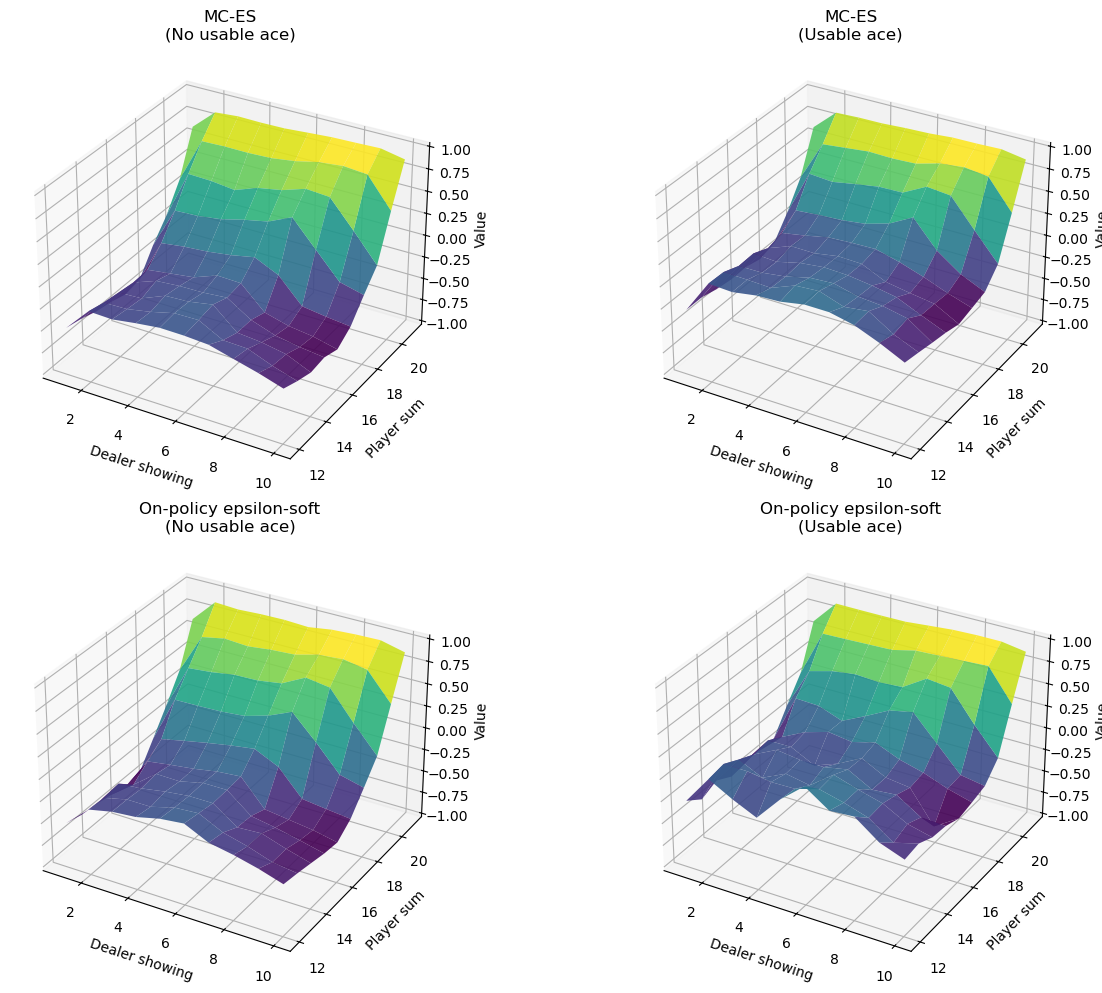

In [58]:
def plot_value_surface(V, title, ax_no_ace, ax_ace):
    dealer = np.arange(1, 11)
    player = np.arange(12, 22)
    X, Y = np.meshgrid(dealer, player)
    for u, ax in enumerate([ax_no_ace, ax_ace]):
        ax.plot_surface(X, Y, V[u], cmap="viridis", edgecolor="none", alpha=0.9)
        ax.set_xlabel("Dealer showing")
        ax.set_ylabel("Player sum")
        ax.set_zlabel("Value")
        sub = "Usable ace" if u == 1 else "No usable ace"
        ax.set_title(f"{title}\n({sub})")
        ax.set_zlim(-1, 1)

fig = plt.figure(figsize=(14, 10))
ax1 = fig.add_subplot(2, 2, 1, projection="3d")
ax2 = fig.add_subplot(2, 2, 2, projection="3d")
ax3 = fig.add_subplot(2, 2, 3, projection="3d")
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
plot_value_surface(V_es, "MC-ES", ax1, ax2)
plot_value_surface(V_eps, "On-policy epsilon-soft", ax3, ax4)
plt.tight_layout()
plt.savefig("value_surfaces.png", dpi=120)
plt.show()

A few things stand out across all four surfaces. The back-right corner is high - sums of 20 and 21 are basically always wins so the value sits near +1. There's a noticeable cliff around player sum 17 where the agent stops hitting and starts sticking, and you can see the surface drop off as you cross that line. The whole surface tilts down from left to right because when the dealer's showing a low card they're more likely to bust themselves, which lifts your value regardless of your hand.
The usable ace surfaces (right column) sit higher overall - having the ace as a fallback if you bust is just strictly better. They're also visibly bumpier than the no-ace surfaces because usable ace states come up much less often in natural play, so they get fewer samples and the estimates are less smooth.

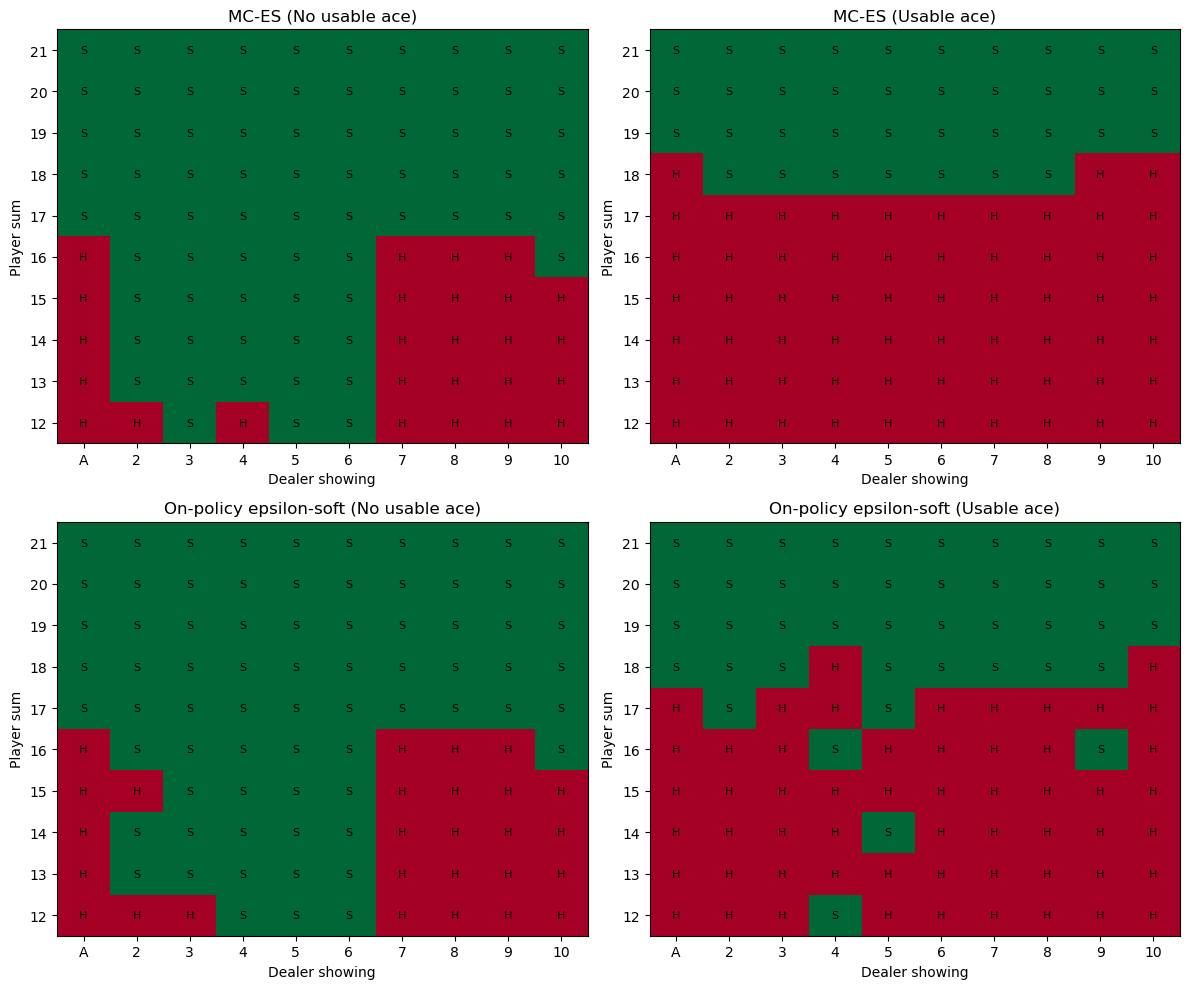

In [59]:
def plot_policy(policy, title, ax_no_ace, ax_ace):
    for u, ax in enumerate([ax_no_ace, ax_ace]):
        ax.imshow(policy[u], cmap="RdYlGn_r", aspect="auto", origin="lower",
                  vmin=0, vmax=1, extent=[0.5, 10.5, 11.5, 21.5])
        ax.set_xticks(range(1, 11))
        ax.set_xticklabels(["A"] + [str(i) for i in range(2, 11)])
        ax.set_yticks(range(12, 22))
        ax.set_xlabel("Dealer showing")
        ax.set_ylabel("Player sum")
        # annotate cells with H/S so it's readable in print too
        for ps in range(10):
            for ds in range(10):
                label = "H" if policy[u, ps, ds] == 1 else "S"
                ax.text(ds + 1, ps + 12, label, ha="center", va="center",
                        fontsize=8, color="black")
        sub = "Usable ace" if u == 1 else "No usable ace"
        ax.set_title(f"{title} ({sub})")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
plot_policy(policy_es, "MC-ES", axes[0, 0], axes[0, 1])
plot_policy(policy_eps, "On-policy epsilon-soft", axes[1, 0], axes[1, 1])
plt.tight_layout()
plt.savefig("policies.png", dpi=120)
plt.show()

The pattern is clearest in the no usable ace panels. Above sum 17 the policy is to stick everywhere - any further hit is more likely to bust than help. Between 12 and 16 the action splits depending on the dealer: stick when the dealer shows 4, 5, or 6 (because those are the dealer's worst cards - they often bust playing them out), and hit when the dealer shows 7 or higher.
With a usable ace the agent hits more aggressively, which makes sense because the ace acts as a safety net. The MC-ES no usable ace panel is the cleanest of the four.

## How long does it take to converge?

Tracking V at one specific state across training. I picked (13, 2, 0) - player has 13, dealer shows 2, no usable ace because it's a state where the optimal action isn't obvious to a human. Good test case.

In [60]:
# Both functions duplicated with logging baked in - cleaner than threading
# a callback through the original training loops

def mc_es_tracked(num_episodes, track_state, seed=0):
    random.seed(seed); np.random.seed(seed)
    env = BlackjackEnv()
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(lambda: np.zeros(2))
    history = []
    for ep in range(num_episodes):
        p_sum = random.randint(12, 21)
        d_show = random.randint(1, 10)
        u_ace = random.randint(0, 1)
        state = env.reset_exploring(p_sum, d_show, u_ace)
        action = random.randint(0, 1)
        episode = []
        done = False
        while not done:
            next_state, reward, done = env.step(action)
            episode.append((state, action, reward))
            state = next_state
            if not done:
                action = int(np.argmax(Q[state]))
        G = 0
        visited = set()
        for (s, a, r) in reversed(episode):
            G = r + G
            if (s, a) not in visited:
                visited.add((s, a))
                N[s][a] += 1
                Q[s][a] += (G - Q[s][a]) / N[s][a]
        if (ep + 1) % 1000 == 0:
            history.append(float(np.max(Q[track_state])))
    return Q, history

def mc_eps_tracked(num_episodes, track_state, epsilon=0.1, seed=0):
    random.seed(seed); np.random.seed(seed)
    env = BlackjackEnv()
    Q = defaultdict(lambda: np.zeros(2))
    N = defaultdict(lambda: np.zeros(2))
    history = []
    for ep in range(num_episodes):
        state = env.reset()
        episode = []
        done = False
        while not done:
            if random.random() < epsilon:
                action = random.randint(0, 1)
            else:
                action = int(np.argmax(Q[state]))
            next_state, reward, done = env.step(action)
            episode.append((state, action, reward))
            state = next_state
        G = 0
        visited = set()
        for (s, a, r) in reversed(episode):
            G = r + G
            if (s, a) not in visited:
                visited.add((s, a))
                N[s][a] += 1
                Q[s][a] += (G - Q[s][a]) / N[s][a]
        if (ep + 1) % 1000 == 0:
            history.append(float(np.max(Q[track_state])))
    return Q, history

Tracking V(13,2,0) across training...


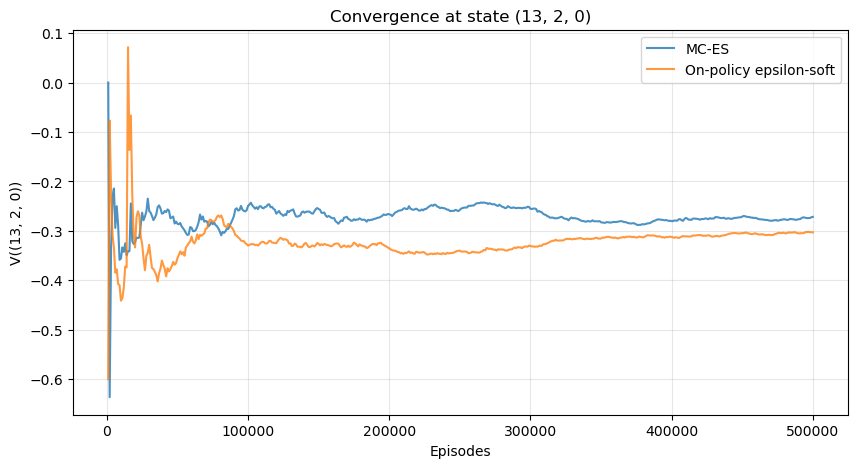

Final V(13, 2, 0): MC-ES = -0.272, epsilon-soft = -0.303


In [61]:
TRACK_STATE = (13, 2, 0)
EPISODES = 500_000

print("Tracking V(13,2,0) across training...")
_, hist_es = mc_es_tracked(EPISODES, TRACK_STATE, seed=0)
_, hist_eps = mc_eps_tracked(EPISODES, TRACK_STATE, epsilon=0.1, seed=0)

plt.figure(figsize=(10, 5))
x = np.arange(1000, EPISODES + 1, 1000)
plt.plot(x, hist_es, label="MC-ES", alpha=0.8)
plt.plot(x, hist_eps, label="On-policy epsilon-soft", alpha=0.8)
plt.xlabel("Episodes")
plt.ylabel(f"V({TRACK_STATE})")
plt.title(f"Convergence at state {TRACK_STATE}")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("convergence.png", dpi=120)
plt.show()

print(f"Final V{TRACK_STATE}: MC-ES = {hist_es[-1]:.3f}, epsilon-soft = {hist_eps[-1]:.3f}")

Both curves are noisy in the first few thousand episodes - one bad hand swings the estimate by a full reward unit and there just aren't enough samples to smooth it out yet. By around 100k things have mostly settled. The two methods converge to slightly different values (MC-ES higher) and that's the e-soft "exploration tax" showing up - the on-policy version is learning the value of a 10% random policy, not the value of the actual greedy policy.

### Policy snapshots at different episode counts

Same algorithm, different amounts of training. Wanted to see how much of the policy is locked in early vs how much is just noise gradually washing out.

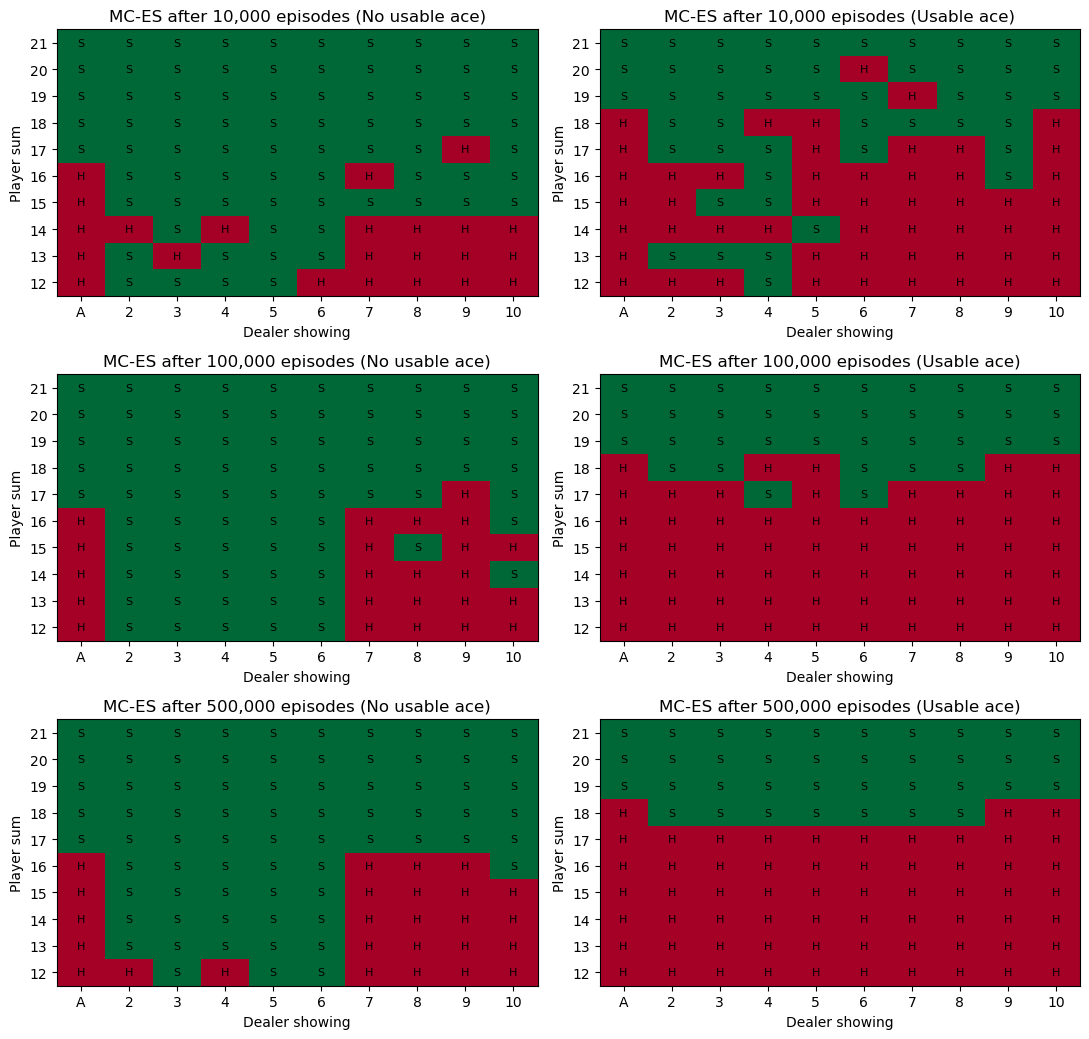

In [62]:
episode_counts = [10_000, 100_000, 500_000]
policies_at = {}
for n in episode_counts:
    Q, _ = mc_exploring_starts(num_episodes=n, seed=0)
    policies_at[n] = extract_policy(Q)

fig, axes = plt.subplots(len(episode_counts), 2, figsize=(11, 3.5 * len(episode_counts)))
for i, n in enumerate(episode_counts):
    plot_policy(policies_at[n], f"MC-ES after {n:,} episodes", axes[i, 0], axes[i, 1])
plt.tight_layout()
plt.savefig("policy_convergence.png", dpi=120)
plt.show()

At 10k the broad shape is already there but rare states (especially the bottom row, player sum 12) are flipping randomly between hit and stick. At 100k most of the policy has settled and it's pretty similar to the 500k version. The last 4× of training mostly cleans up the rare states - which is the sample inefficiency Monte Carlo is known for.

## Performance comparison

100k new games against the dealer, using each learned policy.

In [63]:
def evaluate_policy(policy, num_games=100_000, seed=42):
    random.seed(seed); np.random.seed(seed)
    env = BlackjackEnv()
    wins = losses = draws = 0
    for _ in range(num_games):
        state = env.reset()
        done = False
        reward = 0
        while not done:
            ps, ds, ua = state
            action = int(policy[ua, ps - 12, ds - 1])
            state, reward, done = env.step(action)
        if reward == 1: wins += 1
        elif reward == -1: losses += 1
        else: draws += 1
    return wins / num_games, losses / num_games, draws / num_games

w_es, l_es, d_es = evaluate_policy(policy_es)
w_eps, l_eps, d_eps = evaluate_policy(policy_eps)

print(f"{'Method':<25} {'Win':>6} {'Loss':>6} {'Draw':>6}")
print(f"{'MC-ES':<25} {w_es:>6.3f} {l_es:>6.3f} {d_es:>6.3f}")
print(f"{'On-policy epsilon-soft':<25} {w_eps:>6.3f} {l_eps:>6.3f} {d_eps:>6.3f}")

Method                       Win   Loss   Draw
MC-ES                      0.431  0.476  0.093
On-policy epsilon-soft     0.429  0.478  0.093


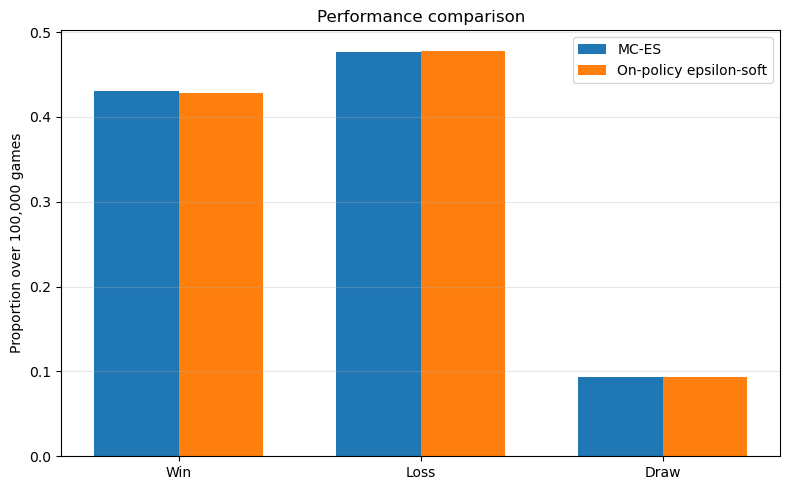

In [64]:
labels = ["Win", "Loss", "Draw"]
es_vals = [w_es, l_es, d_es]
eps_vals = [w_eps, l_eps, d_eps]

x = np.arange(len(labels))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width/2, es_vals, width, label="MC-ES")
ax.bar(x + width/2, eps_vals, width, label="On-policy epsilon-soft")
ax.set_ylabel("Proportion over 100,000 games")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.title("Performance comparison")
plt.tight_layout()
plt.savefig("performance_comparison.png", dpi=120)
plt.show()

## Evaluation

Both methods came out within 0.2 percentage points of each other on win rate (43.1% MC-ES vs 42.9% e-soft over 100k evaluation games), which I think is the main thing worth pulling out. The known optimal win rate for this simplified variant - infinite deck, no doubling, no splitting, dealer stands on 17 - is around 43%, so both methods are essentially as close to optimal as the game allows. The house still wins overall because Blackjack is structurally biased toward the dealer (if the player busts they lose immediately, even if the dealer would've also busted), not because the agent did anything wrong. The policies the agent ended up with also line up with the basic-strategy patterns that experienced players use - hit on low totals against a strong dealer, stick early against a weak one. So it's not just that the algorithm converged to something stable, it converged to a sensible policy.

Where the two methods differ is more interesting than where they agree. MC-ES converges slightly faster on rarely-visited states because exploring starts forces uniform coverage, whereas e-soft only sees rare states as often as they naturally arise. You can see this in the policy snapshot plot - MC-ES at 100k looks cleaner than e-soft would at the same point, especially around player sum 12. On the other hand, MC-ES is unrealistic outside a simulator - you can't actually teleport into arbitrary state-action pairs in most real environments, so for any practical use e-soft is the version you'd reach for. The 0.2 percentage point gap in evaluation performance is the cost of that realism, and it traces back to e-soft learning the value of an e-soft policy rather than the value of the greedy policy itself. The biggest takeaway for me was just how sample-inefficient Monte Carlo is: 500,000 episodes for a 200-state problem is a lot, and the policy at 100k was already pretty good. TD methods like Q-learning would converge in far fewer samples by bootstrapping on each step rather than waiting for terminal returns, which is the obvious next step if I were extending this. Other things I'd want to try given more time: decaying epsilon rather than fixing it at 0.1 (might close the small gap to MC-ES), and adding the missing real Blackjack actions like doubling and splitting which would make the action space and the strategy considerably richer.